# High frequency attributes

Candidate conditioning attributes for the latent upscaler, measured on `axis-v1_1k` images
center-cropped and resized to 1024x1024. All metrics are computed on luminance.

| Attribute | Raw unit | Low → high |
|---|---|---|
| `noise_level` | noise sigma, 8-bit levels (Immerkær estimator on the 20% flattest pixels) | clean → noisy |
| `edge_sharpness` | median peak gradient / local contrast on strong Canny edges, 1/px | soft → crisp edges |
| `texture_detail` | noise-compensated RMS of the two finest band-pass bands outside edges, 8-bit levels | smooth → rich micro-texture |
| `detail_scale` | fraction of texture energy in the finest band | coarse → very fine texture |

Normalized values are empirical-CDF quantiles over the dataset: 0.5 is the median image.

In [1]:
import math
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from stdev.utils.image_tools import crop_maximal_rectangle

REPOSITORY_ROOT = Path.cwd().resolve().parent
DATASET_DIRECTORY = REPOSITORY_ROOT / "datasets" / "axis-v1_1k"
RESIZED_DIRECTORY = REPOSITORY_ROOT / "dev" / "axis-v1_1k_1024"
SORTED_DIRECTORY_PREFIX = REPOSITORY_ROOT / "dev" / "sorted_"
METRICS_TABLE_PATH = REPOSITORY_ROOT / "dev" / "high_frequency_attributes.csv"
NUM_WORKERS = 16

IMAGE_SIZE = 1024
EDGE_BLUR_SIGMA = 1.5
CANNY_LOW_THRESHOLD = 40
CANNY_HIGH_THRESHOLD = 100
EDGE_CONTRAST_WINDOW = 15
MINIMAL_EDGE_CONTRAST = 0.15
MINIMAL_STRONG_EDGE_PIXELS = 100
EDGE_EXCLUSION_RADIUS = 4
FLAT_PIXEL_FRACTION = 0.2
FINE_BAND_SIGMA = 1.0
COARSE_BAND_SIGMA = 2.0
NOISE_KERNEL = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float32)
METRIC_NAMES = ("noise_level", "edge_sharpness", "texture_detail", "detail_scale")

In [2]:
def to_luminance(image: np.ndarray) -> np.ndarray:
    """
    args:
        image: [H, W, 3], channel_order: BGR, pixel_values: [0...255], dtype: uint8
    returns:
        luminance: [H, W], pixel_values: [0...1], dtype: float32
    """
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0


def gaussian_blur(luminance: np.ndarray, sigma: float) -> np.ndarray:
    """
    args:
        luminance: [H, W], dtype: float32
    returns:
        blurred: [H, W], dtype: float32
    """
    return cv2.GaussianBlur(luminance, (0, 0), sigma, borderType=cv2.BORDER_REFLECT)


def band_pass_decomposition(luminance: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Two finest Laplacian-pyramid-like bands at full resolution.

    args:
        luminance: [H, W], dtype: float32
    returns:
        fine_band: [H, W], dtype: float32
        coarse_band: [H, W], dtype: float32
    """
    fine_blurred = gaussian_blur(luminance, FINE_BAND_SIGMA)
    coarse_blurred = gaussian_blur(luminance, COARSE_BAND_SIGMA)
    return luminance - fine_blurred, fine_blurred - coarse_blurred


def compute_white_noise_band_gains() -> tuple[float, float]:
    """
    Variance gains of the band-pass filters for unit-variance white noise.

    returns:
        fine_gain: variance of fine band per unit noise variance
        coarse_gain: variance of coarse band per unit noise variance
    """
    random_generator = np.random.default_rng(0)
    white_noise = random_generator.standard_normal((IMAGE_SIZE, IMAGE_SIZE)).astype(np.float32)
    fine_band, coarse_band = band_pass_decomposition(white_noise)
    return float(fine_band.var()), float(coarse_band.var())


FINE_NOISE_GAIN, COARSE_NOISE_GAIN = compute_white_noise_band_gains()


def detect_edges(luminance: np.ndarray) -> np.ndarray:
    """
    args:
        luminance: [H, W], pixel_values: [0...1], dtype: float32
    returns:
        edges: [H, W], dtype: bool
    """
    blurred = gaussian_blur(luminance, EDGE_BLUR_SIGMA)
    blurred_uint8 = np.clip(blurred * 255.0 + 0.5, 0, 255).astype(np.uint8)
    return cv2.Canny(blurred_uint8, CANNY_LOW_THRESHOLD, CANNY_HIGH_THRESHOLD) > 0


def estimate_noise_level(luminance: np.ndarray) -> float:
    """
    Immerkaer noise sigma estimated on the flattest pixels.

    args:
        luminance: [H, W], pixel_values: [0...1], dtype: float32
    returns:
        noise_sigma: noise standard deviation in 8-bit pixel levels
    """
    noise_response = np.abs(cv2.filter2D(luminance, -1, NOISE_KERNEL))[1:-1, 1:-1]
    blurred = gaussian_blur(luminance, EDGE_BLUR_SIGMA)
    gradient_x = cv2.Sobel(blurred, cv2.CV_32F, 1, 0, ksize=3)
    gradient_y = cv2.Sobel(blurred, cv2.CV_32F, 0, 1, ksize=3)
    structure_magnitude = np.hypot(gradient_x, gradient_y)[1:-1, 1:-1]
    flatness_threshold = np.quantile(structure_magnitude, FLAT_PIXEL_FRACTION)
    flat_responses = noise_response[structure_magnitude <= flatness_threshold]
    kernel_norm = math.sqrt(float((NOISE_KERNEL**2).sum()))
    return float(flat_responses.mean() * math.sqrt(math.pi / 2.0) / kernel_norm * 255.0)


def estimate_edge_sharpness(luminance: np.ndarray, edges: np.ndarray) -> float:
    """
    Median ratio of peak gradient to local edge contrast on strong edges, inverse edge width.

    args:
        luminance: [H, W], pixel_values: [0...1], dtype: float32
        edges: [H, W], dtype: bool
    returns:
        edge_sharpness: [0...~1], 1 / pixels, NaN if the image has too few strong edges
    """
    gradient_x = cv2.Sobel(luminance, cv2.CV_32F, 1, 0, ksize=3) / 8.0
    gradient_y = cv2.Sobel(luminance, cv2.CV_32F, 0, 1, ksize=3) / 8.0
    peak_gradient = cv2.dilate(np.hypot(gradient_x, gradient_y), np.ones((3, 3), np.uint8))
    contrast_kernel = np.ones((EDGE_CONTRAST_WINDOW, EDGE_CONTRAST_WINDOW), np.uint8)
    smoothed = gaussian_blur(luminance, 0.7)
    local_contrast = cv2.dilate(smoothed, contrast_kernel) - cv2.erode(smoothed, contrast_kernel)
    strong_edges = edges & (local_contrast >= MINIMAL_EDGE_CONTRAST)
    if strong_edges.sum() < MINIMAL_STRONG_EDGE_PIXELS:
        return float("nan")
    return float(np.median(peak_gradient[strong_edges] / local_contrast[strong_edges]))


def estimate_texture(
    luminance: np.ndarray, edges: np.ndarray, noise_sigma: float
) -> tuple[float, float]:
    """
    Noise-compensated band-pass energy outside of edges and its fine-band fraction.

    args:
        luminance: [H, W], pixel_values: [0...1], dtype: float32
        edges: [H, W], dtype: bool
        noise_sigma: noise standard deviation in 8-bit pixel levels
    returns:
        texture_detail: RMS of noise-free band-pass signal in 8-bit pixel levels
        detail_scale: [0...1], fraction of texture energy in the finest band
    """
    exclusion_size = 2 * EDGE_EXCLUSION_RADIUS + 1
    exclusion_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (exclusion_size, exclusion_size)
    )
    non_edge = cv2.dilate(edges.astype(np.uint8), exclusion_kernel) == 0
    fine_band, coarse_band = band_pass_decomposition(luminance * 255.0)
    noise_variance = noise_sigma**2
    fine_energy = max(
        0.0, float((fine_band[non_edge] ** 2).mean()) - FINE_NOISE_GAIN * noise_variance
    )
    coarse_energy = max(
        0.0, float((coarse_band[non_edge] ** 2).mean()) - COARSE_NOISE_GAIN * noise_variance
    )
    total_energy = fine_energy + coarse_energy
    detail_scale = fine_energy / total_energy if total_energy > 1e-8 else float("nan")
    return math.sqrt(total_energy), detail_scale


def compute_metrics(image: np.ndarray) -> dict[str, float]:
    """
    args:
        image: [H, W, 3], channel_order: BGR, pixel_values: [0...255], dtype: uint8
    returns:
        metrics: raw values of METRIC_NAMES
    """
    luminance = to_luminance(image)
    edges = detect_edges(luminance)
    noise_level = estimate_noise_level(luminance)
    edge_sharpness = estimate_edge_sharpness(luminance, edges)
    texture_detail, detail_scale = estimate_texture(luminance, edges, noise_level)
    return {
        "noise_level": noise_level,
        "edge_sharpness": edge_sharpness,
        "texture_detail": texture_detail,
        "detail_scale": detail_scale,
    }

## Resize all images and compute metrics

In [3]:
def process_image(image_path: Path) -> dict[str, float | str]:
    """
    Resizes the image to IMAGE_SIZE, saves it as PNG and measures its metrics.
    """
    image = cv2.imread(str(image_path))
    image = crop_maximal_rectangle(image, target_height=IMAGE_SIZE, target_width=IMAGE_SIZE)
    resized_path = RESIZED_DIRECTORY / image_path.parent.name / f"{image_path.stem}.png"
    resized_path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(resized_path), image)
    return {
        "category": image_path.parent.name,
        "name": image_path.stem,
        "resized_path": str(resized_path),
        **compute_metrics(image),
    }


image_paths = sorted(DATASET_DIRECTORY.glob("*/*.jpg"))
with ThreadPoolExecutor(NUM_WORKERS) as executor:
    records = list(tqdm(executor.map(process_image, image_paths), total=len(image_paths)))
metrics_table = pd.DataFrame(records)
print(f"{len(metrics_table)} images")
metrics_table[list(METRIC_NAMES)].describe()

  0%|          | 0/1000 [00:00<?, ?it/s]

1000 images


,noise_level,edge_sharpness,texture_detail,detail_scale
count,1000.000000,998.000000,1000.000000,998.000000
mean,2.434433,0.324618,4.146198,0.772214
std,3.404771,0.066940,2.458795,0.128985
min,0.000000,0.155477,0.000000,0.000000
25%,0.510617,0.277427,2.354330,0.714025
50%,1.463175,0.324619,3.638912,0.796971
75%,2.942891,0.371386,5.451448,0.861331
max,35.250225,0.558171,18.510535,0.980246


## Raw distributions

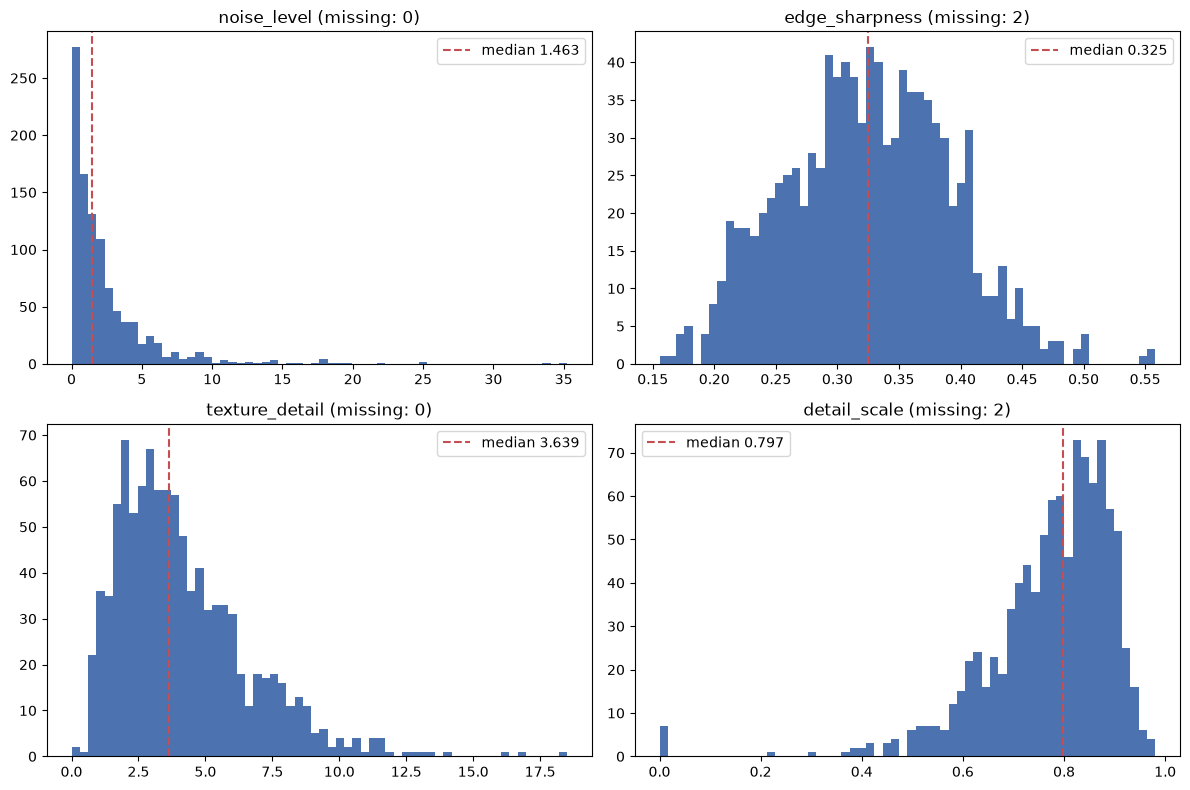

In [ ]:
figure, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, metric_name in zip(axes.flat, METRIC_NAMES):
    values = metrics_table[metric_name].dropna()
    axis.hist(values, bins=60, color="#4C72B0")
    axis.axvline(
        values.median(), color="#C44E52", linestyle="--", label=f"median {values.median():.3f}"
    )
    axis.set_title(f"{metric_name} (missing: {metrics_table[metric_name].isna().sum()})")
    axis.legend()
figure.tight_layout()
plt.show()

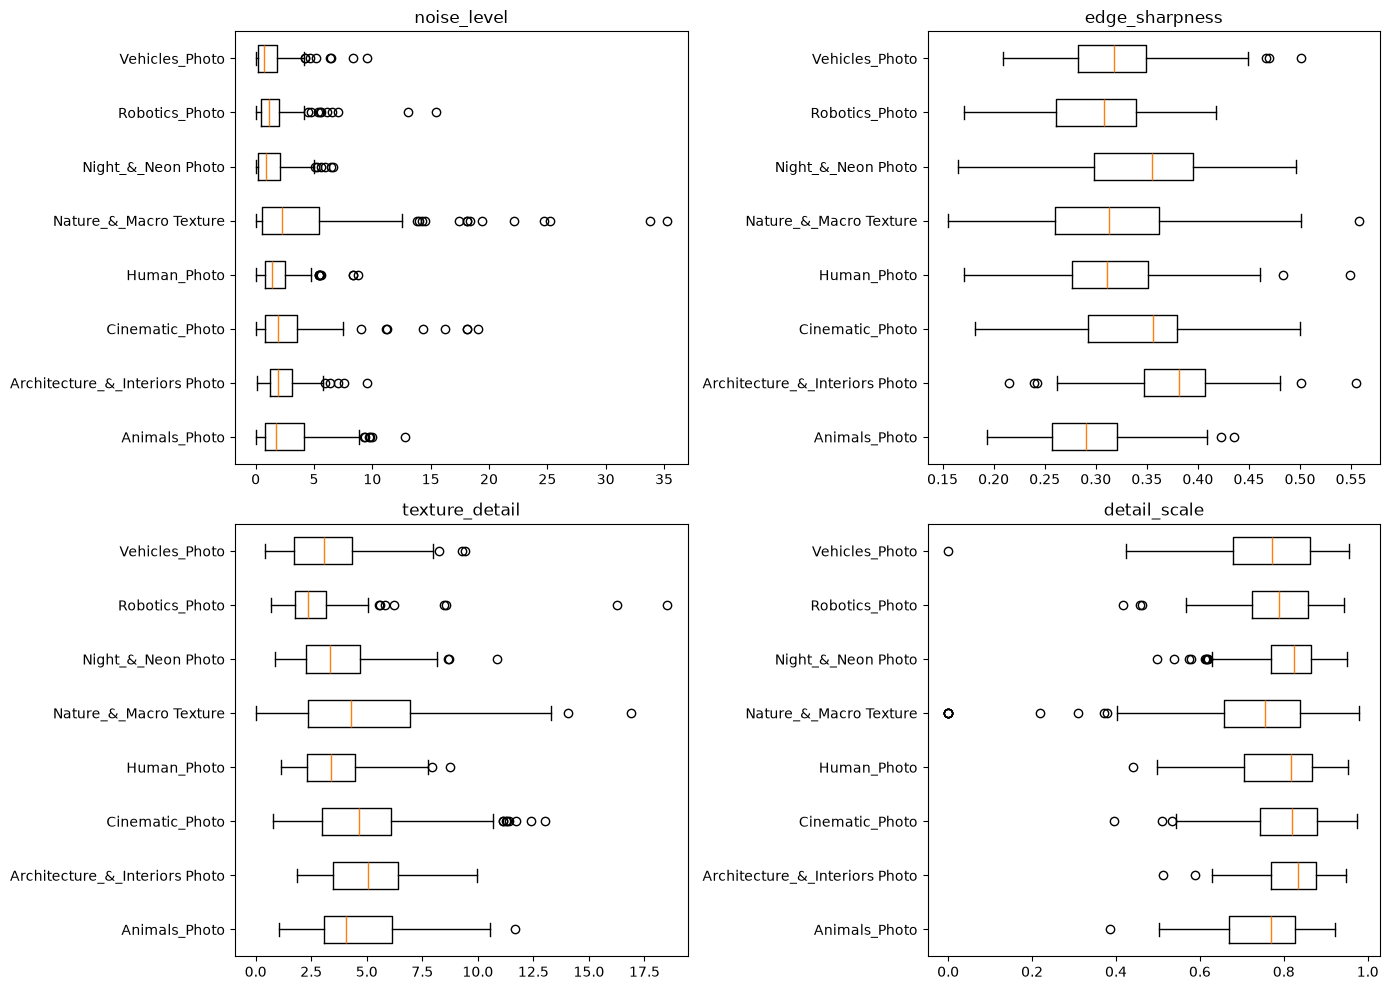

In [5]:
figure, axes = plt.subplots(2, 2, figsize=(14, 10))
category_names = sorted(metrics_table["category"].unique())
for axis, metric_name in zip(axes.flat, METRIC_NAMES):
    category_values = [
        metrics_table.loc[metrics_table["category"] == category_name, metric_name].dropna()
        for category_name in category_names
    ]
    axis.boxplot(category_values, tick_labels=category_names, orientation="horizontal")
    axis.set_title(metric_name)
figure.tight_layout()
plt.show()

## Quantile normalization and correlations

In [6]:
for metric_name in METRIC_NAMES:
    ranks = metrics_table[metric_name].rank(method="average")
    metrics_table[f"{metric_name}_normalized"] = (ranks - 1.0) / (ranks.count() - 1.0)

metrics_table.to_csv(METRICS_TABLE_PATH, index=False)
metrics_table[list(METRIC_NAMES)].corr(method="spearman").round(3)

,noise_level,edge_sharpness,texture_detail,detail_scale
noise_level,1.000,-0.023,0.480,0.154
edge_sharpness,-0.023,1.000,0.305,0.416
texture_detail,0.480,0.305,1.000,0.471
detail_scale,0.154,0.416,0.471,1.000


## Save images sorted by each metric

Files are hard links to the resized PNGs, named `<position>_<normalized value>.png`.

In [7]:
for metric_name in METRIC_NAMES:
    sorted_directory = Path(f"{SORTED_DIRECTORY_PREFIX}{metric_name}")
    sorted_directory.mkdir(parents=True, exist_ok=True)
    for old_path in sorted_directory.glob("*.png"):
        old_path.unlink()
    sorted_table = metrics_table.dropna(subset=[metric_name]).sort_values(metric_name)
    for position, row in enumerate(sorted_table.itertuples()):
        normalized_value = getattr(row, f"{metric_name}_normalized")
        target_path = sorted_directory / f"{position:04d}_{normalized_value:.4f}.png"
        target_path.hardlink_to(row.resized_path)
    print(f"{sorted_directory}: {len(sorted_table)} images")

/home/user/ML/STDev/dev/sorted_noise_level: 1000 images
/home/user/ML/STDev/dev/sorted_edge_sharpness: 998 images
/home/user/ML/STDev/dev/sorted_texture_detail: 1000 images
/home/user/ML/STDev/dev/sorted_detail_scale: 998 images
